In [1]:
import json
import duckdb
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [ ]:
con = duckdb.connect()  # crea un database temporaneo dove posso mandargli request SQL
con.execute("SET TimeZone = 'UTC'")

PATH = "../data/flows.parquet"   # metti il percorso giusto se il file è in un'altra cartella
con.execute(f"CREATE VIEW flows AS SELECT * FROM read_parquet('{PATH}')")

### Descrizione delle colonne

In [4]:
con.sql("DESCRIBE flows").df()

,column_name,column_type,null,key,default,extra
0,flow_id,VARCHAR,YES,None,None,None
1,flow_start,VARCHAR,YES,None,None,None
2,flow_end,VARCHAR,YES,None,None,None
3,start_rtt,DOUBLE,YES,None,None,None
4,end_rtt,DOUBLE,YES,None,None,None
5,delta_rtt,DOUBLE,YES,None,None,None
6,meta.src_ip,VARCHAR,YES,None,None,None
7,meta.dst_ip,VARCHAR,YES,None,None,None
8,meta.src_port,BIGINT,YES,None,None,None
9,meta.dst_port,BIGINT,YES,None,None,None


#### Stampiamo le prime 5 righe 

In [5]:
con.sql("SELECT * FROM flows LIMIT 5").df()

,flow_id,flow_start,flow_end,start_rtt,end_rtt,delta_rtt,meta.src_ip,meta.dst_ip,meta.src_port,meta.dst_port,meta.cric.src.name,meta.cric.dst.name,meta.cric.src.asn,meta.cric.dst.asn,meta.application,meta.experiment_name,meta.activity_id,meta.protocol,meta.ip_version,meta.syslog.hostname,endpoints_match,endpoints_reversed,start_fields_match
0,87bebef6734f137d553a9520164331782b3fc71d71885d...,2026-10-09T13:04:15.139038+00:00,2026-10-09T13:04:16.044906+00:00,94.681,94.900,0.219,2001:660:5009:312:134:158:51:117,2603:4000:c00:0:c:ffff:120c:1bd,55090,1094,IN2P3-CC,MIT_CMS,789,3,MakeReducedNtuple_NANO.x,cms,1,tcp,6,t2dsk0023.cmsaf.mit.edu,False,True,True
1,94c7727cd7142e27c3834777a17e75c2a4f18588b57b04...,2026-10-09T13:04:16.309515+00:00,2026-10-09T13:04:16.491590+00:00,0.140,0.193,0.053,2001:630:10:f001:632:1ff:fe30:b2a0,2001:630:10:f00e::4001,39426,1094,NaN,UKI-LT2-Brunel,<NA>,786,unknown,cms,1,tcp,6,dc2-grid-e6-001.brunel.ac.uk,True,False,True
2,42a76a74451449111b5ad8c30f4e275dda871e51f15021...,2026-10-09T13:04:17.506432+00:00,2026-10-09T13:31:06.098241+00:00,11.638,17.203,5.565,2a00:139c:9:0:47cc:cd42:d167:6063,2001:1458:301:7::100:12,46244,1095,FZK-LCG2,CERN-PROD,58069,513,cmsRun,cms,1,tcp,6,st-120-100gb-b5gddr.cern.ch,False,True,True
3,788f5b2a2a932ad2786158299d6386a8af60db92389b65...,2026-10-09T13:04:17.960352+00:00,2026-10-09T13:08:50.758889+00:00,108.200,113.341,5.141,128.227.78.62,128.142.218.19,37438,1095,UFlorida-HPC,CERN-PROD,6536,513,cmsRun,cms,1,tcp,4,st-096-100gb-ip304-27a7f.cern.ch,False,True,True
4,354e7a239086ce5e459b3d2da3a7c505b858e4c89de319...,2026-10-09T13:04:18.840305+00:00,2026-10-09T13:09:27.461435+00:00,235.812,240.884,5.072,2001:c08:ffff:ffff:ffff:ffff:fffa:94d,2600:900:6:1101:a288:c2ff:fed2:320e,60370,1094,TW-FTT,Nebraska,18217,7896,python3.10,cms,1,tcp,6,red-xfer1.unl.edu,False,True,True


#### Ceerchiamo i NaN nelle colonne

In [6]:
cols = con.sql("DESCRIBE flows").df()["column_name"].tolist()
N = 67_244_519

parts = [f'COUNT(*) - COUNT("{c}") AS "{c}"' for c in cols]
query = "SELECT " + ", ".join(parts) + " FROM flows"

nulls = con.sql(query).df().T
nulls.columns = ["n_null"]
nulls["pct"] = (100 * nulls["n_null"] / N).round(3)
nulls.sort_values("n_null", ascending=False)

,n_null,pct
meta.cric.src.asn,12339289,18.350
meta.cric.src.name,12339289,18.350
meta.cric.dst.name,2707283,4.026
meta.cric.dst.asn,2707283,4.026
meta.application,475477,0.707
endpoints_reversed,0,0.000
endpoints_match,0,0.000
meta.syslog.hostname,0,0.000
meta.ip_version,0,0.000
meta.protocol,0,0.000


#### Cerchiamo stringhe vuote "" oppure UNKDNOWN

In [9]:
desc = con.sql("DESCRIBE flows").df()
str_cols = desc.loc[desc["column_type"] == "VARCHAR", "column_name"].tolist()

parts = [
    f"""COUNT_IF("{c}" = '') AS "{c}__empty",
        COUNT_IF(lower("{c}") = 'unknown') AS "{c}__unknown" """
    for c in str_cols
]
query = "SELECT " + ", ".join(parts) + " FROM flows"
con.sql(query).df().T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0
flow_id__empty,0.0
flow_id__unknown,0.0
flow_start__empty,0.0
flow_start__unknown,0.0
flow_end__empty,0.0
flow_end__unknown,0.0
meta.src_ip__empty,0.0
meta.src_ip__unknown,0.0
meta.dst_ip__empty,0.0
meta.dst_ip__unknown,0.0


In [10]:
con.sql('''
    SELECT
        "meta.cric.src.name" IS NULL AS src_name_null,
        "meta.cric.src.asn"  IS NULL AS src_asn_null,
        "meta.cric.dst.name" IS NULL AS dst_name_null,
        "meta.cric.dst.asn"  IS NULL AS dst_asn_null,
        COUNT(*) AS n
    FROM flows
    GROUP BY ALL
    ORDER BY n DESC
''').df()

,src_name_null,src_asn_null,dst_name_null,dst_asn_null,n
0,False,False,False,False,52712239
1,True,True,False,False,11824997
2,False,False,True,True,2192991
3,True,True,True,True,514292


#### Distribuzione degli RTT

In [11]:
rows = []
for c in ["start_rtt", "end_rtt", "delta_rtt"]:
    r = con.sql(f"""
        SELECT
            MIN({c})                   AS min,
            approx_quantile({c}, 0.01) AS p01,
            approx_quantile({c}, 0.25) AS p25,
            approx_quantile({c}, 0.50) AS p50,
            approx_quantile({c}, 0.75) AS p75,
            approx_quantile({c}, 0.99) AS p99,
            MAX({c})                   AS max,
            AVG({c})                   AS mean,
            STDDEV({c})                AS std,
            COUNT_IF({c} < 0)          AS n_neg,
            COUNT_IF({c} = 0)          AS n_zero
        FROM flows
    """).df()
    r.index = [c]
    rows.append(r)

pd.concat(rows)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,min,p01,p25,p50,p75,p99,max,mean,std,n_neg,n_zero
start_rtt,0.00,0.120127,9.853907,17.811789,46.531869,249.376342,32182.000,39.005657,54.114775,0.0,773.0
end_rtt,0.00,0.155023,14.579717,21.839635,47.555367,249.816561,120322.084,42.365450,124.413888,0.0,357462.0
delta_rtt,-14993.52,-9.040385,0.062510,4.440819,5.245751,15.541012,120016.873,3.359794,113.216026,9679068.0,242527.0


In [12]:
con.sql('''
    SELECT
        endpoints_match,
        endpoints_reversed,
        COUNT(*)                                               AS n,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)     AS pct_rows,
        approx_quantile(delta_rtt, 0.25)                       AS d_p25,
        approx_quantile(delta_rtt, 0.50)                       AS d_p50,
        approx_quantile(delta_rtt, 0.75)                       AS d_p75,
        ROUND(100.0 * COUNT_IF(delta_rtt < 0) / COUNT(*), 2)   AS pct_neg,
        COUNT_IF(end_rtt = 0)                                  AS n_end_zero
    FROM flows
    GROUP BY ALL
    ORDER BY n DESC
''').df()

,endpoints_match,endpoints_reversed,n,pct_rows,d_p25,d_p50,d_p75,pct_neg,n_end_zero
0,False,True,44629463,66.37,1.636156,4.952988,5.368470,10.60,8003.0
1,True,False,22615056,33.63,0.003031,0.061998,2.672747,21.88,349459.0


In [13]:
con.sql('''
    WITH f AS (
        SELECT
            endpoints_reversed,
            delta_rtt,
            epoch(CAST(flow_end AS TIMESTAMPTZ))
              - epoch(CAST(flow_start AS TIMESTAMPTZ)) AS duration_s
        FROM flows
    )
    SELECT
        CASE
            WHEN duration_s < 1    THEN '1) < 1 s'
            WHEN duration_s < 10   THEN '2) 1-10 s'
            WHEN duration_s < 60   THEN '3) 10-60 s'
            WHEN duration_s < 600  THEN '4) 1-10 min'
            ELSE                        '5) > 10 min'
        END                               AS duration_bucket,
        endpoints_reversed,
        COUNT(*)                          AS n,
        approx_quantile(delta_rtt, 0.50)  AS d_p50,
        approx_quantile(delta_rtt, 0.25)  AS d_p25,
        approx_quantile(delta_rtt, 0.75)  AS d_p75
    FROM f
    GROUP BY ALL
    ORDER BY duration_bucket, endpoints_reversed
''').df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,duration_bucket,endpoints_reversed,n,d_p50,d_p25,d_p75
0,1) < 1 s,False,8840510,0.046635,0.004142,0.324417
1,1) < 1 s,True,1921390,0.476298,0.113383,3.245786
2,2) 1-10 s,False,4630439,0.035249,-0.000425,1.721908
3,2) 1-10 s,True,2369511,0.779698,0.023783,4.880209
4,3) 10-60 s,False,3046205,0.064694,-0.001362,5.091213
5,3) 10-60 s,True,2247586,4.198731,0.309241,5.237487
6,4) 1-10 min,False,4933667,2.818166,0.009454,5.332808
7,4) 1-10 min,True,22908939,4.941017,4.267567,5.347043
8,5) > 10 min,False,1164235,0.262023,0.000066,4.931609
9,5) > 10 min,True,15182037,5.133973,2.170871,5.504975


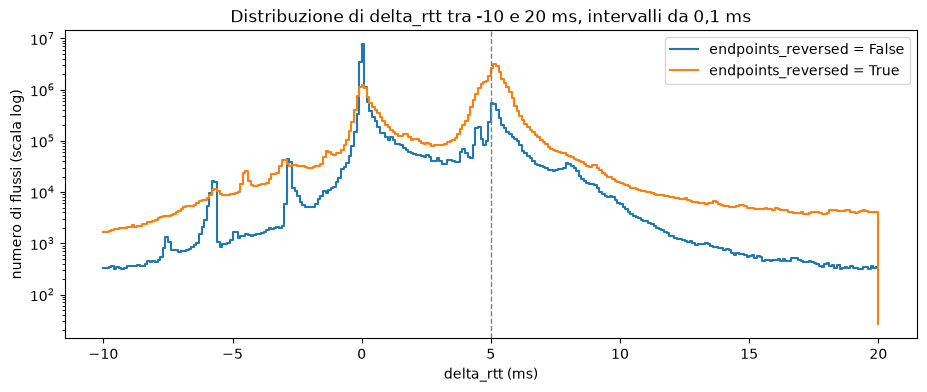

In [14]:
import matplotlib.pyplot as plt

h = con.sql('''
    SELECT
        floor(delta_rtt / 0.1) * 0.1  AS bin,
        endpoints_reversed,
        COUNT(*)                      AS n
    FROM flows
    WHERE delta_rtt BETWEEN -10 AND 20
    GROUP BY ALL
    ORDER BY bin
''').df()

fig, ax = plt.subplots(figsize=(11, 4))
for flag, g in h.groupby("endpoints_reversed"):
    ax.step(g["bin"], g["n"], where="post", label=f"endpoints_reversed = {flag}")

ax.axvline(5, linestyle="--", color="gray", linewidth=1)
ax.set_yscale("log")
ax.set_xlabel("delta_rtt (ms)")
ax.set_ylabel("numero di flussi (scala log)")
ax.set_title("Distribuzione di delta_rtt tra -10 e 20 ms, intervalli da 0,1 ms")
ax.legend()
plt.show()

In [15]:
con.sql('''
    SELECT
        CASE
            WHEN start_rtt < 0.1 THEN '1) < 0.1 ms'
            WHEN start_rtt < 1   THEN '2) 0.1-1 ms'
            WHEN start_rtt < 10  THEN '3) 1-10 ms'
            WHEN start_rtt < 100 THEN '4) 10-100 ms'
            ELSE                      '5) >= 100 ms'
        END       AS start_rtt_bucket,
        COUNT(*)  AS n
    FROM flows
    WHERE end_rtt = 0
    GROUP BY ALL
    ORDER BY start_rtt_bucket
''').df()

,start_rtt_bucket,n
0,1) < 0.1 ms,8
1,2) 0.1-1 ms,1
2,3) 1-10 ms,50347
3,4) 10-100 ms,298300
4,5) >= 100 ms,8806


In [16]:
con.sql('''
    SELECT
        MIN(start_rtt) FILTER (WHERE start_rtt > 0) AS min_pos_start,
        MIN(end_rtt)   FILTER (WHERE end_rtt   > 0) AS min_pos_end
    FROM flows
''').df()

,min_pos_start,min_pos_end
0,0.007,0.002


In [17]:
con.sql('''
    SELECT
        "meta.cric.src.name"                                 AS src,
        "meta.cric.dst.name"                                 AS dst,
        COUNT(*)                                             AS n_tot,
        COUNT_IF(end_rtt = 0)                                AS n_zero,
        ROUND(100.0 * COUNT_IF(end_rtt = 0) / COUNT(*), 2)   AS pct_zero,
        approx_quantile(start_rtt, 0.5)                      AS start_p50
    FROM flows
    GROUP BY ALL
    HAVING COUNT_IF(end_rtt = 0) > 0
    ORDER BY n_zero DESC
    LIMIT 20
''').df()

,src,dst,n_tot,n_zero,pct_zero,start_p50
0,MIT_CMS,USCMS-FNAL-WC1,133890,118830.0,88.75,20.542577
1,Nebraska,USCMS-FNAL-WC1,105950,100761.0,95.10,58.809538
2,GLOW,USCMS-FNAL-WC1,84841,57359.0,67.61,5.780691
3,GLOW,NaN,141905,28362.0,19.99,56.816367
4,NaN,USCMS-FNAL-WC1,29297,22437.0,76.58,74.055210
5,UCSDT2,USCMS-FNAL-WC1,21216,21216.0,100.00,74.161170
6,KR-KNU-T3,CERN-PROD,29438,7730.0,26.26,254.802226
7,RAL-LCG2,CERN-PROD,2502122,216.0,0.01,22.259683
8,GSI-LCG2,CERN-PROD,751407,171.0,0.02,10.243077
9,NaN,CERN-PROD,8125778,77.0,0.00,16.910382


In [18]:
con.sql('''
    SELECT
        "meta.cric.src.name"              AS src,
        "meta.cric.dst.name"              AS dst,
        COUNT(*)                          AS n,
        approx_quantile(end_rtt, 0.5)     AS end_p50
    FROM flows
    WHERE start_rtt = 0
    GROUP BY ALL
    ORDER BY n DESC
    LIMIT 10
''').df()

,src,dst,n,end_p50
0,IN2P3-IRES,GRIF,438,16.836111
1,TW-FTT,RAL-LCG2,62,279.860000
2,NIKHEF-ELPROD,RAL-LCG2,39,31.703000
3,NaN,CERN-PROD,27,176.642000
4,TW-FTT,UKI-SCOTGRID-GLASGOW,22,224.104500
5,FZK-LCG2,GRIF,22,24.992000
6,FZK-LCG2,UKI-SCOTGRID-GLASGOW,18,28.491000
7,TW-FTT,UKI-NORTHGRID-LANCS-HEP,12,220.375500
8,NIKHEF-ELPROD,CERN-PROD,12,16.489000
9,INFN-T1,CERN-PROD,10,9.774000


### TOGLIAMO LE 300000 righe con NULL

In [24]:
splits = json.load(open("../data/splits.json"))
TRAIN_END = splits["train_end_inclusive"]
VAL_END   = splits["validation_end_inclusive"]

con.execute(f'''
    CREATE OR REPLACE VIEW flows_clean AS
    SELECT
        *,
        CAST(flow_start AS TIMESTAMPTZ) AS t_start,
        CASE
            WHEN CAST(flow_start AS TIMESTAMPTZ) <= TIMESTAMPTZ '{TRAIN_END}' THEN 'train'
            WHEN CAST(flow_start AS TIMESTAMPTZ) <= TIMESTAMPTZ '{VAL_END}'   THEN 'val'
            ELSE 'test'
        END AS split
    FROM flows
    WHERE start_rtt > 0 AND end_rtt > 0
''');

con.sql("SELECT split, COUNT(*) AS n FROM flows_clean GROUP BY split ORDER BY split").df()

,split,n
0,test,10086352
1,train,46730686
2,val,10069254


## Pulizia dei dati

### Dataset di partenza
- **File:** `flows.parquet` (release v1, creata il 2026-10-16), 67.244.519 flussi ricostruiti, 23 colonne.
- **Unità di osservazione:** ogni riga è un flusso, ottenuto accoppiando un evento firefly di *start* e uno di *end* tramite la chiave `(flow_id, flow_start)`. La ricostruzione a monte ha già escluso gruppi ambigui, duplicati o senza coppia, timestamp non ordinati ed RTT non finiti o nulli.
- **Periodo coperto:** inizio dei flussi dal 2026-10-07 23:59:59 al 2026-10-14 23:59:59 UTC.
- **Target:** `delta_rtt = end_rtt − start_rtt`.
- **Unità degli RTT:** non dichiarata dal README. I valori sono compatibili con i **millisecondi** (es. ~0,1 ms tra macchine dello stesso sito, ~11 ms Karlsruhe–CERN, ~95 ms Lione–MIT, ~236 ms Taiwan–Nebraska). Risoluzione minima osservata: 0,002 ms.

### Valori mancanti
I campi principali (IP, porte, timestamp, RTT, protocollo, versione IP, esperimento, attività, hostname) **non hanno valori NULL** né stringhe vuote.

| Campo | NULL | % | Note |
|---|---|---|---|
| `meta.cric.src.name` / `meta.cric.src.asn` | 12.339.289 | 18,35% | mancano sempre insieme |
| `meta.cric.dst.name` / `meta.cric.dst.asn` | 2.707.283 | 4,03% | mancano sempre insieme |
| `meta.application` | 475.477 | 0,71% | + 5.541.029 valori `unknown` (8,24%) |
| `meta.experiment_name` | 0 | 0% | 289.901 valori `unknown` (0,43%) |

Combinazioni di sito/ASN mancanti: entrambi i lati noti 78,4%, solo sorgente ignota 17,6%, solo destinazione ignota 3,3%, entrambi ignoti 0,8%.

Nome del sito e ASN provengono da un **arricchimento** esterno (catalogo CRIC della WLCG) a partire dall'IP: se l'IP non è registrato in CRIC, entrambi restano NULL. L'asimmetria sorgente/destinazione è compatibile con il fatto che le destinazioni sono soprattutto server di storage registrati, mentre le sorgenti includono worker node e client meno censiti.

**Nessuna imputazione è stata applicata.** Opzioni da confrontare in fase di modellazione:
- (A) token dedicato `SITE_MISSING`;
- (B) ricostruzione del sito dal prefisso IP, solo quando il prefisso è univoco nel train, con flag di imputazione;
- (C) uso diretto del prefisso IP (sempre disponibile) al posto del sito.

Per `meta.application`, NULL e `unknown` sono per ora trattati come due categorie distinte.

### Righe escluse: RTT pari a zero
**Regola:** si escludono i flussi con `start_rtt = 0` oppure `end_rtt = 0`. Il filtro è applicato in **tutti** gli split, perché riguarda la validità del target e non costituisce leakage.

**Motivazione.** Un RTT nullo non è una misura fisica ma una misura mancata:
- **Fine del flusso (357.462 righe, 0,53%).** Il 99,99% di questi flussi ha `start_rtt ≥ 1 ms` (298.300 tra 10 e 100 ms, 8.806 sopra i 100 ms). Un percorso di rete non può passare da decine di millisecondi a zero durante un trasferimento, e la risoluzione della misura (0,002 ms) esclude un arrotondamento a zero.
- **Gli zeri sono concentrati su un sito.** Circa il 90% riguarda flussi verso **USCMS-FNAL-WC1** (Fermilab), con percentuali di zeri fino al 100% per alcune coppie (UCSDT2 → FNAL 100%, Nebraska → FNAL 95%, MIT_CMS → FNAL 89%). Sulle coppie più frequenti senza FNAL (es. RAL → CERN, GSI → CERN) la quota è ≤ 0,02%. Questo indica un problema sistematico del produttore di telemetria su quel sito, non un comportamento della rete.
- **Inizio del flusso (773 righe, 0,001%).** Sparsi su coppie diverse e senza legame con FNAL. L'RTT finale di questi flussi è normale (es. 17 ms IN2P3-IRES → GRIF, 280 ms TW-FTT → RAL): anche lo zero iniziale è una misura mancata, probabilmente presa prima del primo campione di RTT.
- 8 righe avevano entrambi gli RTT a zero.

**Perché non tenerle.** Con un RTT nullo il target diventerebbe `delta_rtt = −start_rtt`, un calo fittizio. Il modello imparerebbe a riprodurre il guasto del sensore (es. "flusso verso FNAL → forte calo dell'RTT") invece del comportamento della rete. I flussi verso FNAL con misure valide **restano** nel dataset.

**Righe rimosse per split:**

| Split | Originali | Dopo la pulizia | Rimosse | % |
|---|---|---|---|---|
| train | 47.071.163 | 46.730.686 | 340.477 | 0,72% |
| val | 10.086.678 | 10.069.254 | 17.424 | 0,17% |
| test | 10.086.678 | 10.086.352 | 326 | 0,003% |
| **totale** | **67.244.519** | **66.886.292** | **358.227** | **0,53%** |

La quota di zeri cala fortemente nel tempo: il problema sembra essersi risolto durante la settimana coperta dai dati.

**Limiti introdotti.**
- **Bias di selezione su FNAL:** alcune coppie verso FNAL spariscono (UCSDT2 → FNAL) o restano molto ridotte. Se la misura fallisce più spesso in certi tipi di trasferimento, i flussi FNAL rimasti potrebbero non essere rappresentativi. L'errore del modello sui flussi FNAL andrà valutato separatamente.
- I `delta_rtt` **negativi** sono stati **mantenuti**: rappresentano un calo reale dell'RTT durante il trasferimento.
- Gli **outlier estremi** (|`delta_rtt`| fino a ~15.000 e ~120.000) sono per ora mantenuti; l'eventuale taglio sarà deciso in fase di modellazione, con soglie calcolate solo sul train.

### Osservazioni sul target
- `delta_rtt` ha una distribuzione **bimodale**: un picco stretto intorno a 0 e uno intorno a **~5 ms**, con code lunghe in entrambe le direzioni (p01 = −9,0; p50 = 4,4; p99 = 15,5 ms).
- Il picco a ~5 ms riguarda soprattutto i **trasferimenti lunghi** (mediana ~5 ms sopra il minuto di durata) ed è presente in entrambi i valori di `endpoints_reversed`. La differenza iniziale tra i due gruppi (mediana 4,95 contro 0,06 ms) è in gran parte dovuta a un **confondimento con la durata**: i flussi `reversed` sono quasi tutti lunghi, quelli `match` soprattutto brevi.
- Ipotesi da verificare: il valore costante di ~5 ms, indipendente dalla distanza geografica, è compatibile con il **ritardo di coda obiettivo di fq_codel** (5 ms di default nei sistemi Linux).
- La **durata** del flusso è fortemente legata al target ma **non può essere usata come input**, perché richiede l'evento di end. Lo stesso vale per `end_rtt`, `flow_end`, `endpoints_match`, `endpoints_reversed` e `start_fields_match`.
- Metrica: con code così pesanti, l'RMSE sarebbe dominato da pochi outlier. Si riportano MAE e RMSE, privilegiando il MAE.

### Domande aperte per il CERN
1. Il picco a ~5 ms nei trasferimenti lunghi è un fenomeno reale di coda (es. fq_codel) o una differenza tra gli strumenti che misurano start ed end?
2. Gli `end_rtt = 0` concentrati su USCMS-FNAL-WC1 sono un problema noto del produttore, ed è stato corretto durante la settimana?
3. Le slide parlano di "RTT prediction", il README indica `delta_rtt` come target: confermiamo che il target è `delta_rtt`?

### Tipi di dati per categoria 

In [19]:
cat_cols = [
    "meta.src_ip", "meta.dst_ip",
    "meta.src_port", "meta.dst_port",
    "meta.cric.src.name", "meta.cric.dst.name",
    "meta.cric.src.asn", "meta.cric.dst.asn",
    "meta.application", "meta.experiment_name", "meta.activity_id",
    "meta.protocol", "meta.ip_version", "meta.syslog.hostname",
]

parts = [f'approx_count_distinct("{c}") AS "{c}"' for c in cat_cols]
card = con.sql("SELECT " + ", ".join(parts) + " FROM flows").df().T
card.columns = ["n_distinct"]
card.sort_values("n_distinct", ascending=False)

,n_distinct
meta.src_port,63876
meta.dst_port,63791
meta.src_ip,26772
meta.dst_ip,6915
meta.syslog.hostname,789
meta.application,186
meta.cric.src.name,89
meta.cric.dst.name,77
meta.cric.src.asn,63
meta.cric.dst.asn,58
